In [1]:
from datetime import time

from ech_discovery.data.ingest.ech import (
    ECH_SUCCESSFUL_IN_DNS,
    ECH_SUCCESSFUL_NO_DNS,
    error_mapping,
    split_success_by_ech_in_dns,
)
from ech_discovery.notebook import *

In [2]:
order = [
    ECH_SUCCESSFUL_IN_DNS,
    ECH_SUCCESSFUL_NO_DNS,
    *sorted({v for k, v in error_mapping.items() if k is not None}),
]

tab20 = sns.color_palette("tab20")
tab10 = sns.color_palette("tab10")

palette = {
    ECH_SUCCESSFUL_IN_DNS: tab20[0], 
    ECH_SUCCESSFUL_NO_DNS: tab20[1],
    **{label: tab10[i] for i, label in enumerate(order[2:], start=1)},
}

In [3]:
df = (
    (
        cv.load_data("error_statistics_followed_domains")
        .filter(pl.col(C.location) == "tud")
        .filter(RANGES["error-stats"].expr() | RANGES["followup"].expr())
        .collect()
    )
    .with_columns(
        (pl.col(C.target) / pl.col(C.target).sum().over(C.measurement) * 100).alias(
            C.len_percent
        )
    )
    .rename({C.error_reason: C.label})
    .with_columns(pl.col(C.label).replace(error_mapping))
    .pipe(split_success_by_ech_in_dns)  # <-- add this line
    .group_by(C.measurement, C.location, C.label)
    .agg(
        pl.col(C.target).sum(),
        pl.col(C.len_percent).sum(),
    )
    .with_columns(pl.col(C.measurement).dt.truncate("1d"))
    .with_columns(pl.col(C.label).cast(pl.Enum(order)))
    .sort([C.measurement, C.location, C.label], descending=[False, False, False])
    .with_columns(
        pl.col(C.len_percent).cum_sum().over(C.measurement, C.location),
        pl.col(C.len_percent).alias(C.len_percent_raw),
    )
)
df

measurement,location,label,target,len [%],len [%]-raw
datetime[μs],str,enum,u32,f64,f64
2025-07-14 00:00:00,"""tud""","""ECH with Configuration in DNS""","1,994,118",61.075552,61.075552
2025-07-14 00:00:00,"""tud""","""ECH without Configuration in D…","1,270,884",100.0,38.924448
2025-07-16 00:00:00,"""tud""","""ECH with Configuration in DNS""","1,982,283",60.713072,60.713072
…,…,…,…,…,…
2026-08-15 00:00:00,"""tud""","""TCP Error""","24,981",97.888945,0.765114
2026-08-15 00:00:00,"""tud""","""TLS Error""","68,926",100.0,2.111055


In [4]:
assert (
    df.filter(pl.col(C.len_percent) > 100.01).select(pl.len()).item() == 0
), "Significantly more than 100% is impossible. Aggregation error."

/mnt/data01/artifacts-active-ech/06-ech-analysis/reports/figures/ech-consistency/bar_ech_consistency.png


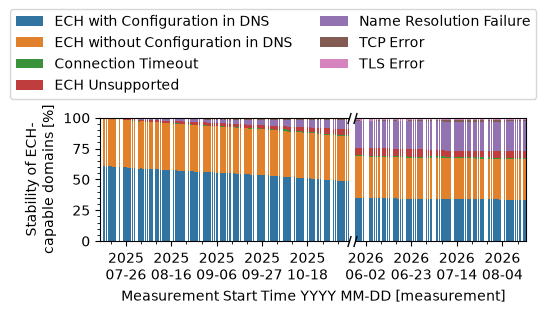

In [5]:
fig, axs = vh.fig_ax(
    (5.5, 1.6),
    ncols=2,
    sharey="row",
    gridspec_kw={
        "wspace": 0.03,
        "width_ratios": [
            RANGES["error-stats"].duration.days,
            RANGES["followup"].duration.days,
        ],
    },
)
vh.mark_axis_break(axs[0], axs[1])
axs[1].tick_params(axis="y", which="minor", left=False, right=False, labelleft=False)

for ax, key in zip(axs.flatten(), ["error-stats", "followup"]):
    sns.barplot(
        df.filter(RANGES[key].expr()),
        x=C.measurement,
        y=C.len_percent,
        hue=C.label,
        native_scale=True,
        dodge=False,
        hue_order=order[::-1],
        palette=sns.color_palette("tab10", 7)[::-1],
        ax=ax,
    )

    vh.set_time_format(
        ax.xaxis,
        "%Y\n%m-%d",
        C.measurement,
        Strings.measurement_start_time,
    )
    if ax == axs[0]:
        ax.set(ylabel=Strings.domains_subsequent_ech)
        ax.legend().remove()

    if ax == axs[1]:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(
            handles=handles[::-1],
            labels=labels[::-1],
            ncol=2,
            frameon=True,
            edgecolor="0.8",
            loc="lower right",
            bbox_to_anchor=(1.1, 1.1),
        )
        ax.set(xlabel=None)

    ax.yaxis.set_minor_locator(ticker.MultipleLocator(5))
    ax.set(ylim=(0, 100))
    ax.set(
        xlim=(
            datetime.combine(RANGES[key].start, time()),
            datetime.combine(RANGES[key].end, time()),
        )
    )

    ax.xaxis.set_major_locator(mdates.DayLocator(interval=21))
    ax.xaxis.set_minor_locator(mdates.DayLocator(interval=7))


vh.center_label(fig, axs, "x")

ax.set(xlabel=None)
vh.save_plot(fig, "bar_ech_consistency", config.FIGURES_DIR / "ech-consistency")